<a href="https://colab.research.google.com/github/sabrinachu-47/memory-demand-forecast/blob/main/notebooks/memory_demand_forecast.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

               value
date                
2026-04-01  176.6948
2026-05-01  184.1891
2026-06-01  187.5187
2026-07-01  190.2607
2026-08-01  190.0987


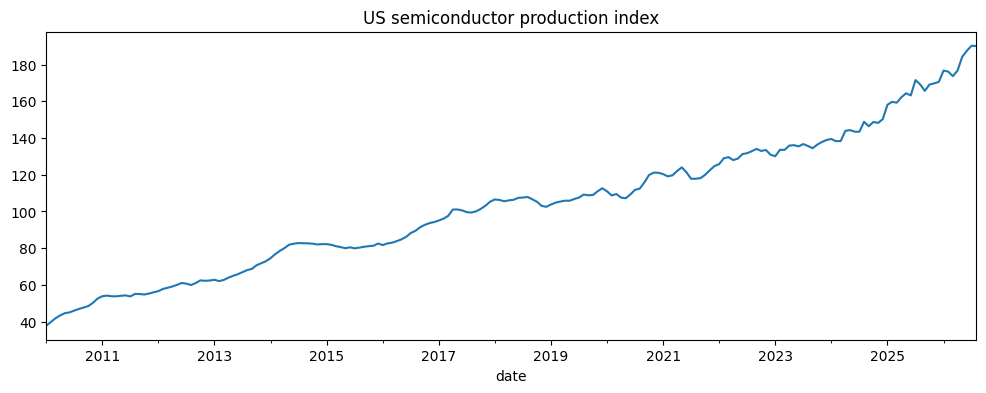

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=IPG3344S"
#The “S” at the end of IPG3344S means seasonal patterns have already been removed
df = pd.read_csv(url)
df.columns = ["date", "value"]
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")
df = df[df.index >= "2010-01-01"]

print(df.tail())
df["value"].plot(figsize=(12, 4), title="US semiconductor production index")
plt.show()

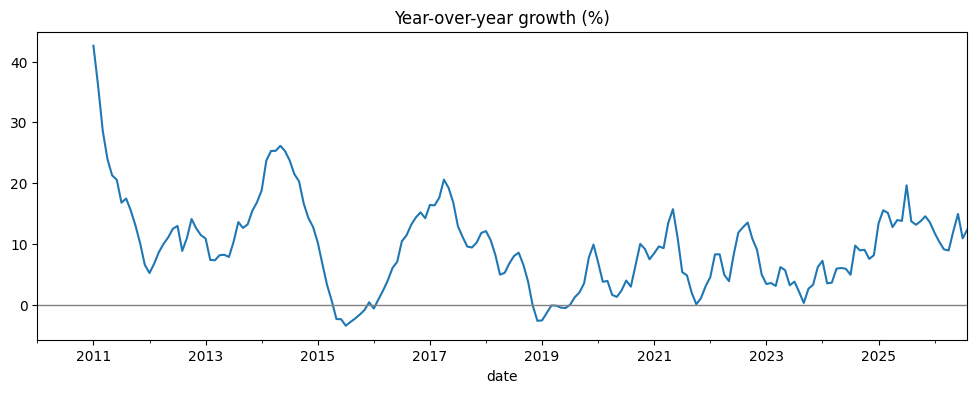

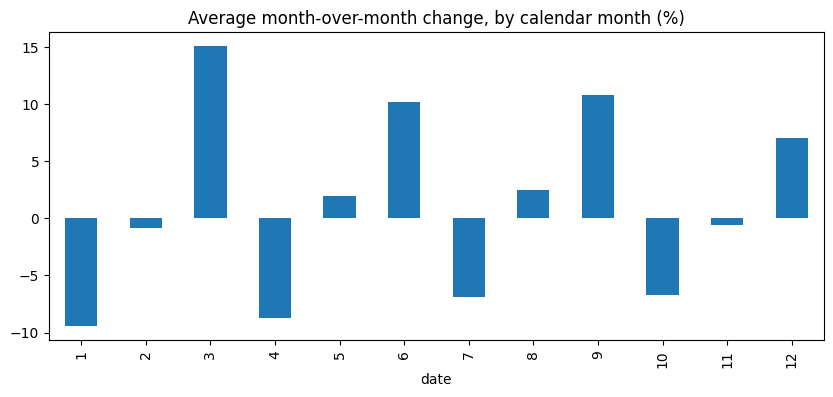

In [ ]:
# 1. Year-over-year growth: % change vs. the same month last year
df["yoy_pct"] = df["value"].pct_change(12) * 100
#pct_change(12) compares each month to the same month 12 months earlier

fig, ax = plt.subplots(figsize=(12, 4))
df["yoy_pct"].plot(ax=ax, title="Year-over-year growth (%)")
ax.axhline(0, color="gray", linewidth=1)
#axhline(0) draws a line at zero. Anything below it means shrinking versus last year
plt.show()

# 2. Unadjusted version of the same series (N = not seasonally adjusted)
raw = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=IPG3344N")
raw.columns = ["date", "value_nsa"]
raw["date"] = pd.to_datetime(raw["date"])
raw = raw.set_index("date")
df = df.join(raw)

# Average month-over-month change for each calendar month
df["mom_pct"] = df["value_nsa"].pct_change() * 100
by_month = df.groupby(df.index.month)["mom_pct"].mean()
by_month.plot(kind="bar", figsize=(10, 4), title="Average month-over-month change, by calendar month (%)")
plt.show()

Chart 1: Year-over-year growth. Growth moves in clear cycles. It peaks roughly every three years (2014, 2017, 2021, 2025) and falls to around zero or below in downturns (2015–16, 2019, 2022–23). Since 2019, the swings have been smaller, and growth has stayed positive for several years. This is consistent with the view that the current upcycle may last longer than past ones. However, this index covers all US semiconductor production, not just memory, so it can’t confirm that on its own. I’ll test it later with memory-specific data.

Chart 2: Average month-over-month change by calendar month. Production rises sharply in the last month of each quarter (March, June, September, December) and drops in the first month (January, April, July, October). This is likely a quarter-end effect: early in a quarter, orders are still being negotiated, and toward the end, companies push shipments to hit quarterly financial targets. Because of this, month-to-month swings shouldn’t be read as real changes in underlying demand. Comparing quarters, or the same month year over year, gives a truer picture.

Growth rate used: 4.7%

                         MAPE %  WMAPE %  Bias %
Naive                      12.1     12.5   -12.5
Seasonal naive             15.9     16.2   -16.2
Seasonal naive + growth    10.0     10.2   -10.2


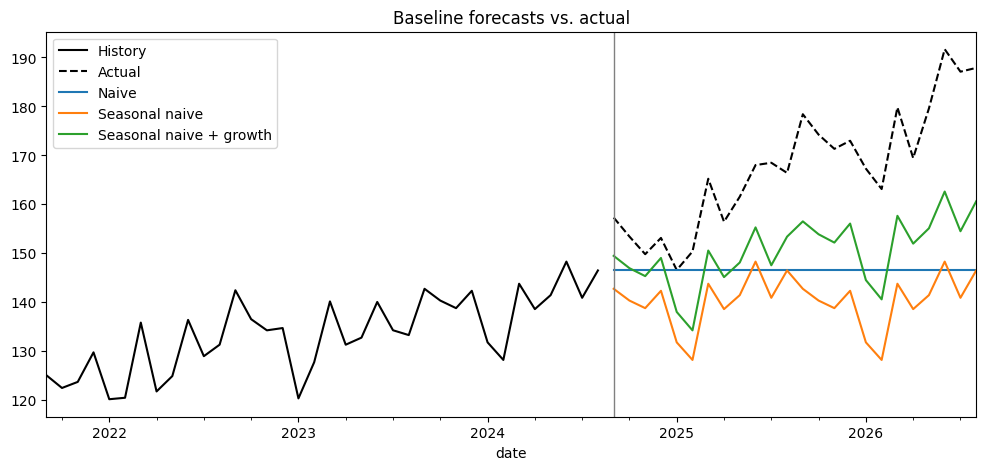

In [ ]:
import numpy as np

# The series we're forecasting: unadjusted production
y = df["value_nsa"].dropna()

# Split: everything before the last 24 months is "known", the last 24 are the test
h = 24
train, test = y[:-h], y[-h:]

# 1. Naive: repeat the last known value
naive = pd.Series(train.iloc[-1], index=test.index)

# 2. Seasonal naive: repeat the last 12 known months
last_year = train.iloc[-12:].values
snaive = pd.Series(np.resize(last_year, h), index=test.index)

# 3. Seasonal naive + growth: last year's pattern, grown at last year's rate
growth = train.iloc[-12:].sum() / train.iloc[-24:-12].sum() - 1
snaive_growth = pd.Series(
    [last_year[i % 12] * (1 + growth) ** (i // 12 + 1) for i in range(h)],
    index=test.index,
)

forecasts = {"Naive": naive, "Seasonal naive": snaive, "Seasonal naive + growth": snaive_growth}
#Naive: next month equals this month, repeated forever. A flat line.
#Seasonal naive: next year looks exactly like last year. It copies the last 12 months.
#Seasonal naive + growth: last year’s pattern, scaled up by last year’s growth rate. This adds the trend. -- > BEST Accuracy

# Accuracy metrics
def score(actual, forecast):
    err = forecast - actual
    mape = (err.abs() / actual).mean() * 100
    wmape = err.abs().sum() / actual.sum() * 100
    bias = err.sum() / actual.sum() * 100
    return round(mape, 1), round(wmape, 1), round(bias, 1)

results = pd.DataFrame(
    {name: score(test, fc) for name, fc in forecasts.items()},
    index=["MAPE %", "WMAPE %", "Bias %"],
).T
print(f"Growth rate used: {growth:.1%}\n")
print(results)

# Chart: recent history, what actually happened, and the three forecasts
fig, ax = plt.subplots(figsize=(12, 5))
train[-36:].plot(ax=ax, color="black", label="History")
test.plot(ax=ax, color="black", linestyle="--", label="Actual")
for name, fc in forecasts.items():
    fc.plot(ax=ax, label=name)
ax.axvline(test.index[0], color="gray", linewidth=1)
ax.set_title("Baseline forecasts vs. actual")
ax.legend()
plt.show()

**Step 2: Baseline forecasts.** I held out the last 24 months (Sep 2024 to Aug 2026) and tested three simple forecasts using only data up to Aug 2024.

**Best baseline.** Seasonal naive + growth performed best on every metric (WMAPE 10.2%, bias −10.2%). It kept last year's quarter-end pattern and added a growth rate, so its shape closely matched the actual data.

**Negative bias.** All three forecasts had negative bias, meaning they consistently under-forecast. The growth model assumed 4.7% growth based on the prior year, but actual growth accelerated to roughly 10–15% in 2025–26, so the gap widened over time. In practice, under-forecasting like this would lead to too few wafer starts, missed sales, and customers being put on allocation.

**Naive vs. seasonal naive.** The naive forecast (a flat line) scored better than seasonal naive (WMAPE 12.5% vs. 16.2%), even though it missed every quarter-end swing. It only won because it started from a higher point. This shows that a lower error score doesn't always mean a more useful forecast, so results should be checked visually, not just by metrics.

**Next step.** The seasonal forecasts got the shape right but the level wrong. A better model needs to keep the seasonal pattern while updating the trend as new data arrives.

                           MAPE %  WMAPE %  Bias %
ETS additive season           7.2      7.5    -7.4
ETS multiplicative season     7.6      7.9    -7.7
ETS damped trend              9.3      9.6    -9.5
Seasonal naive + growth      10.0     10.2   -10.2
Naive                        12.1     12.5   -12.5
Seasonal naive               15.9     16.2   -16.2


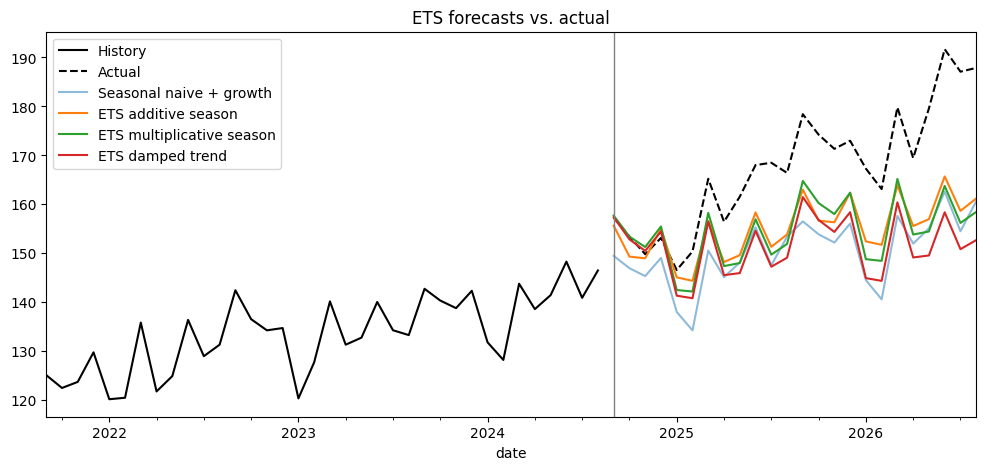

In [ ]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import warnings
warnings.filterwarnings("ignore")

# Tell Python the data is monthly (needed by the model)
train_m = train.asfreq("MS")

ets_versions = {
    "ETS additive season": dict(trend="add", seasonal="add"),
    "ETS multiplicative season": dict(trend="add", seasonal="mul"),
    "ETS damped trend": dict(trend="add", damped_trend=True, seasonal="mul"),
}

for name, settings in ets_versions.items():
    model = ExponentialSmoothing(train_m, seasonal_periods=12, **settings).fit()
    fc = model.forecast(h)
    fc.index = test.index
    forecasts[name] = fc

# Score every model (baselines + ETS), best WMAPE at the top
results = pd.DataFrame(
    {name: score(test, fc) for name, fc in forecasts.items()},
    index=["MAPE %", "WMAPE %", "Bias %"],
).T.sort_values("WMAPE %")
print(results)

# Chart: actual vs. best baseline vs. the ETS models
fig, ax = plt.subplots(figsize=(12, 5))
train[-36:].plot(ax=ax, color="black", label="History")
test.plot(ax=ax, color="black", linestyle="--", label="Actual")
forecasts["Seasonal naive + growth"].plot(ax=ax, label="Seasonal naive + growth", alpha=0.5)
for name in ets_versions:
    forecasts[name].plot(ax=ax, label=name)
ax.axvline(test.index[0], color="gray", linewidth=1)
ax.set_title("ETS forecasts vs. actual")
ax.legend()
plt.show()

**Step 3: Exponential smoothing (ETS).** I tested three ETS models on the same 24-month holdout. ETS tracks the level, trend, and seasonal pattern separately and gives more weight to recent data.

**Results.** All three ETS models beat every baseline. The best was ETS with additive seasonality (WMAPE 7.5%), about 25% less error than the best baseline, seasonal naive + growth (WMAPE 10.2%). Additive and multiplicative seasonality performed almost the same (7.5% vs. 7.9%), so the choice between them matters little for this data.

**Bias is still strongly negative (−7.4% for the best model).** ETS only saw data through Aug 2024, when growth was moderate, so it could not anticipate the acceleration in 2025–26. A better model reduced the error but could not fix a change in the trend it never observed.

**Damped trend hurt.** Damping assumes growth will gradually slow down. Actual growth sped up instead, so the damped model fell further behind (WMAPE 9.6%, bias −9.5%). Damping is useful when growth is expected to cool, but it is the wrong assumption during an upswing.

**Accuracy drops with horizon.** ETS tracked actual closely for the first 3–4 months, then the gap widened. This suggests short-term forecasts are much more reliable than long-term ones, which I will measure directly in the next step.

Total forecasts scored: 1,530

Overall:
                           WMAPE %  Bias %
model                                     
ETS additive season            3.4    -2.1
ETS multiplicative season      3.7    -2.6
Seasonal naive + growth        4.0    -1.3 

WMAPE % by horizon (months ahead):
model    ETS additive season  ETS multiplicative season  \
horizon                                                   
1                        1.8                        1.9   
2                        2.3                        2.5   
3                        2.7                        2.8   
4                        3.0                        3.3   
5                        3.2                        3.4   
6                        3.1                        3.5   
7                        3.5                        4.0   
8                        3.7                        4.2   
9                        4.2                        4.5   
10                       4.6                        4.8   


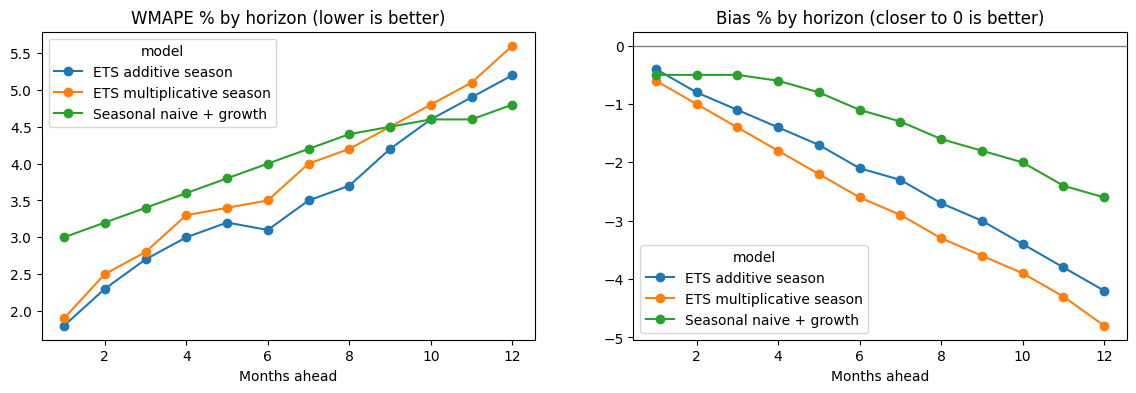

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
y_m = y.asfreq("MS")
max_h = 12

# Every month from Aug 2022 up to the second-to-last month is a "forecast date"
origins = y_m.index[(y_m.index >= "2022-08-01") & (y_m.index < y_m.index[-1])]

def fc_snaive_growth(hist, n):
    last = hist.iloc[-12:].values
    g = hist.iloc[-12:].sum() / hist.iloc[-24:-12].sum() - 1
    return [last[i % 12] * (1 + g) ** (i // 12 + 1) for i in range(n)]

def fc_ets(hist, n, seasonal):
    m = ExponentialSmoothing(hist, trend="add", seasonal=seasonal, seasonal_periods=12).fit()
    return list(m.forecast(n))

models = {
    "Seasonal naive + growth": lambda hist, n: fc_snaive_growth(hist, n),
    "ETS additive season": lambda hist, n: fc_ets(hist, n, "add"),
    "ETS multiplicative season": lambda hist, n: fc_ets(hist, n, "mul"),
}

rows = []
for origin in origins:
    hist = y_m[:origin]                              # data known at the forecast date
    future = y_m[y_m.index > origin][:max_h]         # what actually happened next
    for name, model_fn in models.items():
        preds = model_fn(hist, len(future))
        for i, (date, actual) in enumerate(future.items()):
            rows.append({
                "model": name, "forecast_date": origin, "target_date": date,
                "horizon": i + 1, "forecast": preds[i], "actual": actual,
            })

bt = pd.DataFrame(rows)
bt["error"] = bt["forecast"] - bt["actual"]
print(f"Total forecasts scored: {len(bt):,}\n")

# Score by model and horizon
def summarize(g):
    return pd.Series({
        "WMAPE %": g["error"].abs().sum() / g["actual"].sum() * 100,
        "Bias %": g["error"].sum() / g["actual"].sum() * 100,
    })

print("Overall:")
print(bt.groupby("model").apply(summarize).round(1), "\n")

summary = bt.groupby(["model", "horizon"]).apply(summarize).reset_index()
wmape_table = summary.pivot(index="horizon", columns="model", values="WMAPE %").round(1)
bias_table = summary.pivot(index="horizon", columns="model", values="Bias %").round(1)
print("WMAPE % by horizon (months ahead):")
print(wmape_table, "\n")
print("Bias % by horizon:")
print(bias_table)

# Charts: accuracy and bias by horizon
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
wmape_table.plot(ax=axes[0], marker="o", title="WMAPE % by horizon (lower is better)")
bias_table.plot(ax=axes[1], marker="o", title="Bias % by horizon (closer to 0 is better)")
axes[1].axhline(0, color="gray", linewidth=1)
for a in axes:
    a.set_xlabel("Months ahead")
plt.show()

# Save results for Tableau
bt.to_csv("backtest_results.csv", index=False)
from google.colab import files
files.download("backtest_results.csv")

**Step 4: Rolling backtest.** To score the models the way planners actually forecast, I re-ran each model every month from Aug 2022 onward, refitting on the latest data and forecasting 12 months ahead each time. This produced 1,530 scored forecasts, grouped by horizon (how many months ahead).

**Accuracy drops with horizon.** The best model, ETS with additive seasonality, had a WMAPE of 1.8% one month ahead and 5.2% twelve months ahead, nearly three times higher. Overall WMAPE was 3.4%, much better than the single-origin test in Step 3 (7.5%), because the model now updates with new data every month.

**Bias is negative at every horizon and grows with distance.** Bias was close to zero one month ahead (−0.4%) but reached −4.2% at twelve months. Short-term forecasts correct quickly as new data arrives, while long-range forecasts keep assuming the slower past growth rate, so under-forecasting compounds during an upswing.

**The best model depends on the horizon.** ETS additive was most accurate for months 1–9. Seasonal naive + growth caught up at months 10–12 and had the smallest bias at almost every horizon. This suggests using a responsive model for near-term planning and a steadier one for longer-range planning, although the long-horizon differences are small and based on fewer forecasts.

**Limitation.** This is a single national aggregate, which is smoother and easier to forecast than product- or customer-level demand. Real forecasts at that level would have much higher error.

Saving kioxia_quarterly.csv to kioxia_quarterly.csv
Check: Kioxia's stated price change vs. the one we calculated (% QoQ)
        fiscal_quarter  asp_pct_stated  asp_pct_implied
quarter                                                
2023Q2         FY23 Q1            -5.0            -11.0
2023Q3         FY23 Q2             8.0              9.2
2023Q4         FY23 Q3            12.0              8.5
2024Q1         FY23 Q4            18.0             13.8
2024Q2         FY24 Q1            20.0             18.8
2024Q3         FY24 Q2             5.0              2.0
2024Q4         FY24 Q3            -2.0             -4.5
2025Q1         FY24 Q4           -20.0            -14.3
2025Q2         FY25 Q1             8.0             -1.2
2025Q3         FY25 Q2            -2.0             -4.5
2025Q4         FY25 Q3            12.0             15.5
2026Q1         FY25 Q4           100.0            105.0
2026Q2         FY26 Q1            70.0             72.7 

        fiscal_quarter  Revenue  Vol

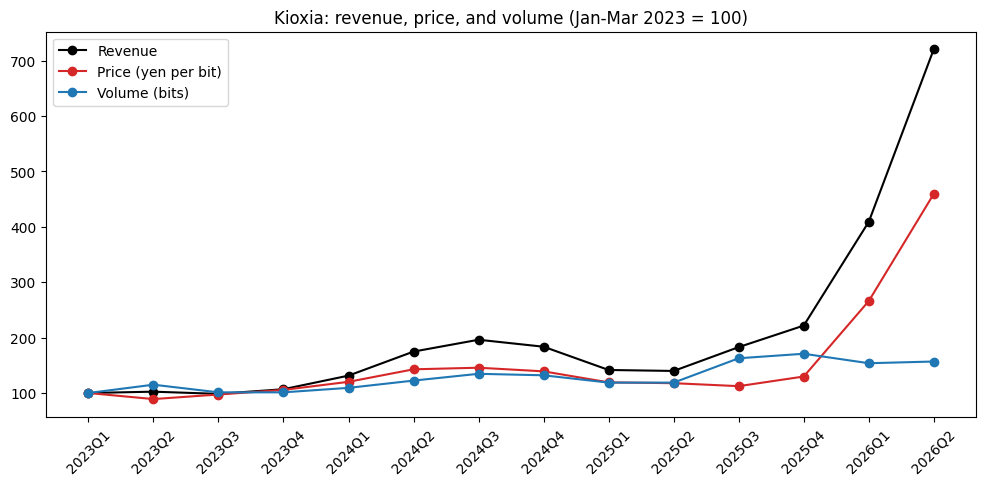

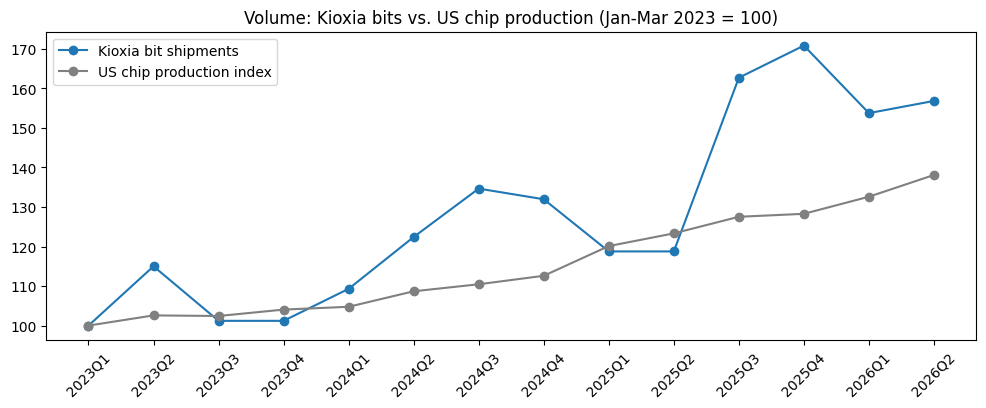

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# 1. Upload and load the Kioxia table
files.upload()   # choose kioxia_quarterly.csv
k = pd.read_csv("kioxia_quarterly.csv")
k["quarter"] = pd.PeriodIndex(k["calendar_quarter"].str.replace(" ", ""), freq="Q")
k = k.set_index("quarter")

# 2. Turn Kioxia's wording into numbers (% change vs. previous quarter)
bit_words = {
    "Mid-teens % increase": 15, "Low-teens % decrease": -12, "Flat": 0,
    "High-single-digit % increase": 8, "Low-teens % increase": 12,
    "Around 10% increase": 10, "Low-single-digit % decrease": -2,
    "Around 10% decrease": -10, "High 30% increase": 37,
    "Mid-single-digit % increase": 5, "Low-single-digit % increase": 2,
}
asp_words = {
    "Mid-single-digit % decline": -5, "High-single-digit % increase": 8,
    "Low-teens % increase": 12, "High-teens % increase": 18,
    "Around 20% increase": 20, "Mid-single-digit % increase": 5,
    "Low-single-digit % decrease": -2, "Around 20% decrease": -20,
    "Low-10% range increase": 12, "More than doubled": 100, "About 70% increase": 70,
}
k["bit_pct"] = k["bit_growth_qoq"].map(bit_words)
k["asp_pct_stated"] = k["asp_change_qoq"].map(asp_words)

# 3. Price change implied by revenue and volume: (1 + revenue growth) / (1 + bit growth) - 1
k["rev_pct"] = k["revenue_jpy_bn"].pct_change() * 100
k["asp_pct_implied"] = ((1 + k["rev_pct"] / 100) / (1 + k["bit_pct"] / 100) - 1) * 100

# 4. Build indexes starting at 100 in Jan-Mar 2023 (the quarter before our bit data begins)
base = pd.Period("2023Q1", freq="Q")
s = k.loc[base:].copy()
s["Volume (bits)"] = 100 * (1 + s["bit_pct"].fillna(0) / 100).cumprod()
s["Revenue"] = 100 * s["revenue_jpy_bn"] / s.loc[base, "revenue_jpy_bn"]
s["Price (yen per bit)"] = s["Revenue"] / s["Volume (bits)"] * 100

print("Check: Kioxia's stated price change vs. the one we calculated (% QoQ)")
print(s[["fiscal_quarter", "asp_pct_stated", "asp_pct_implied"]].round(1).dropna(), "\n")

# 5. Add the US production index from Step 1, averaged by quarter, same starting point
fred = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=IPG3344S")
fred.columns = ["date", "value"]
fred["date"] = pd.to_datetime(fred["date"])
prod_q = fred.set_index("date")["value"].resample("QE").mean().to_period("Q")
s["US chip production (FRED)"] = 100 * prod_q.reindex(s.index) / prod_q[base]

print(s[["fiscal_quarter", "Revenue", "Volume (bits)", "Price (yen per bit)",
         "US chip production (FRED)"]].round(0))

# Chart 1: Kioxia revenue split into volume and price
labels = s.index.astype(str)
fig, ax = plt.subplots(figsize=(12, 5))
for col, color in [("Revenue", "black"), ("Price (yen per bit)", "tab:red"), ("Volume (bits)", "tab:blue")]:
    ax.plot(labels, s[col], marker="o", color=color, label=col)
ax.set_title("Kioxia: revenue, price, and volume (Jan-Mar 2023 = 100)")
ax.legend()
plt.xticks(rotation=45)
plt.show()

# Chart 2: two volume measures side by side
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(labels, s["Volume (bits)"], marker="o", color="tab:blue", label="Kioxia bit shipments")
ax.plot(labels, s["US chip production (FRED)"], marker="o", color="gray", label="US chip production index")
ax.set_title("Volume: Kioxia bits vs. US chip production (Jan-Mar 2023 = 100)")
ax.legend()
plt.xticks(rotation=45)
plt.show()

# Save for Tableau
out = s.reset_index()
out["quarter"] = out["quarter"].astype(str)
out.to_csv("kioxia_price_volume.csv", index=False)
files.download("kioxia_price_volume.csv")

**Step 5b: Kioxia revenue split into volume and price.** I collected 13 quarters of Kioxia revenue and bit-growth disclosures (FY23 Q1 to FY26 Q1), converted Kioxia's wording into numbers, and calculated price per bit as revenue ÷ volume.

**Validation.** My calculated price change matched Kioxia's stated ASP change within about 5 points in 11 of 13 quarters. The largest gap, FY25 Q1 (stated +8%, calculated −1%), is explained by currency: Kioxia reports ASP in US dollars from FY25 onward, while my calculation is in yen, and the yen strengthened that quarter.

**Price drove most of the growth.** From Jan–Mar 2023 to Apr–Jun 2026, revenue grew 7.2x, price per bit 4.6x, and volume only 1.6x. Roughly three-quarters of revenue growth came from price. In the latest two quarters, volume fell while revenue tripled, the signature of a supply shortage.

**Growth came in different forms.** In 2025Q3, revenue growth was almost entirely volume-driven (bits +37%), while in 2026 it was almost entirely price-driven. For planning, these call for different responses: volume growth requires more supply, while price-driven growth signals demand exceeding supply and a need to allocate product.

**Volume measures.** Kioxia's bit shipments (+57%) were far more volatile than the US semiconductor production index (+38%). The production index rose steadily and showed no sign of the boom, confirming that memory cycles show up mainly in prices, not volumes. This explains why the cycles were muted in Step 1.

**Limitations.** Bit growth and ASP are converted from ranges (e.g., "mid-teens" = 15%), so each quarter's figure is approximate. The US production index covers all semiconductors and is US-only, while Kioxia is a global NAND supplier.